# Project Deliverable 2: ML Engine (Ridge Regression base model)

**Project:** Skill Exchange and Service Evaluation App
**Group members:** Alicia Maryanne, Charlotte Mujuri, Lyon Agina

## What this notebook does (in simple words)
Our app lets two people swap services. For a swap to be fair, the app needs to know roughly **how much each service is worth**.
This notebook builds that "value estimator": a model that reads a service (its category, sub-category, title, rating and number of reviews) and predicts its price.

- **ML task:** supervised learning, regression (predict a number: the price)
- **Base model:** Ridge Regression (linear regression with regularisation)
- **Dataset:** a Fiverr services listing (6,183 rows, 7 columns)
- **Later use in the app:** if service A is worth more than service B, the app suggests a cash top-up or an extra service to even it out.

**Notebook outline**
1. Load and explore the data
2. Data cleaning
3. Exploratory data analysis (4+ observations)
4. Modelling with Ridge (cross-validation + choosing alpha)
5. Using the model for fair exchanges (app workflow demo)
6. Validation plan: comparing against other models (Question 4)

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and explore the data
First we look at the raw data exactly as it came, before changing anything.

In [2]:
DATA_PATH = "fiverr.csv"   # upload fiverr.csv to Colab (Files panel) or change this path
df = pd.read_csv(DATA_PATH)

rows, columns = df.shape
print("Rows:", rows, "| Columns:", columns)
df.head()

Rows: 6183 | Columns: 7


,Category,Category-href,Subcat,Subcat-href,name,stars,price
0,Programming & Tech,https://www.fiverr.com/categories/programming-...,Data Analysis & Reports,https://www.fiverr.com/categories/programming-...,I will build automated and insightful power bi...,5.0(10),Starting at€137.76
1,Lifestyle,https://www.fiverr.com/categories/lifestyle?so...,Greeting Cards & Videos,https://www.fiverr.com/categories/lifestyle/gr...,I will get kermit to personalize a video birth...,5.0(1k+),Starting at€4.44
2,Programming & Tech,https://www.fiverr.com/categories/programming-...,Website Builders & CMS,https://www.fiverr.com/categories/programming-...,I will build or redesign your existing squares...,5.0(68),Starting at€66.66
3,Lifestyle,https://www.fiverr.com/categories/lifestyle?so...,Cooking Lessons,https://www.fiverr.com/categories/lifestyle/co...,I will create original eastern food cooking vi...,4.9(5),Starting at€17.78
4,Writing & Translation,https://www.fiverr.com/categories/writing-tran...,Legal Writing,https://www.fiverr.com/categories/writing-tran...,I will write gdpr privacy policy and terms and...,5.0(2),Starting at€8.89


In [3]:
# Data types and missing values in the raw data
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nFully duplicated rows:", df.duplicated().sum())
print("Distinct categories:", df["Category"].nunique(), "| Distinct sub-categories:", df["Subcat"].nunique())

Category         object
Category-href    object
Subcat           object
Subcat-href      object
name             object
stars            object
price            object
dtype: object

Missing values per column:
Category           0
Category-href      0
Subcat             0
Subcat-href        0
name               0
stars            493
price              0
dtype: int64

Fully duplicated rows: 1
Distinct categories: 7 | Distinct sub-categories: 129


**Problems found in the raw data**
- `price` is text like `Starting at€137.76`, so it cannot be used as a number yet.
- `stars` is text like `5.0(10)` (rating and number of reviews stuck together) and `1k+` means "1000 or more". It also has missing values.
- Some `Subcat` names end with a leftover "New" or "Beta" tag (e.g. `Podcast EditingNew`, `Local PhotographyBeta`).
- `Category-href` and `Subcat-href` are web links. They do not describe the service, so they are not useful for prediction.
- Possible duplicate rows.

## 2. Data cleaning
Each step is done on a copy (`clean`) so the original `df` stays untouched.

In [4]:
clean = df.copy()

# Step 1: drop the link columns (they only point to web pages, they do not describe the service)
clean = clean.drop(columns=["Category-href", "Subcat-href"])

# Step 2: turn "Starting at€137.76" into the number 137.76
clean["price_eur"] = (
    clean["price"].str.extract(r"€\s*([\d,]+\.?\d*)")[0]
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Step 3: split "5.0(1k+)" into a rating (5.0) and a review count (1000)
parts = clean["stars"].str.extract(r"^([\d.]+)\(([\d.]+)(k?)\+?\)$")
clean["rating"] = parts[0].astype(float)
clean["reviews"] = parts[1].astype(float) * np.where(parts[2] == "k", 1000, 1)

# Check that every non-missing 'stars' value was understood
unparsed = clean["stars"].notna() & clean["rating"].isna()
print("Stars values that could not be parsed:", unparsed.sum())

# Step 4: missing stars means the seller has no reviews yet.
# We keep rating as missing (filled later, inside the model pipeline, using training data only)
# and record the fact that there are no reviews.
clean["reviews"] = clean["reviews"].fillna(0)
clean["has_reviews"] = clean["stars"].notna().astype(int)

# Step 5: remove the leftover "New" / "Beta" tags from sub-category names
clean["Subcat"] = clean["Subcat"].str.replace(r"(?<=[a-z])(New|Beta)$", "", regex=True).str.strip()

# Step 6: tidy the service title: lower case and remove the common "I will " start
clean["service"] = (
    clean["name"].str.lower()
    .str.replace(r"^i will\s+", "", regex=True)
    .str.strip()
)

# Step 7: drop the old text columns we have replaced
clean = clean.drop(columns=["name", "stars", "price"])

# Step 8: remove duplicate rows
before = len(clean)
clean = clean.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", before - len(clean))

clean.head()

Stars values that could not be parsed: 0
Duplicate rows removed: 1


,Category,Subcat,price_eur,rating,reviews,has_reviews,service
0,Programming & Tech,Data Analysis & Reports,137.76,5.0,10.0,1,build automated and insightful power bi report
1,Lifestyle,Greeting Cards & Videos,4.44,5.0,1000.0,1,get kermit to personalize a video birthday gre...
2,Programming & Tech,Website Builders & CMS,66.66,5.0,68.0,1,build or redesign your existing squarespace we...
3,Lifestyle,Cooking Lessons,17.78,4.9,5.0,1,create original eastern food cooking video recipe
4,Writing & Translation,Legal Writing,8.89,5.0,2.0,1,write gdpr privacy policy and terms and condit...


In [5]:
# Step 9: outliers. Check how extreme the high prices are (IQR rule)
q1, q3 = clean["price_eur"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_out = (clean["price_eur"] > upper_fence).sum()
print(f"Prices above the IQR fence (EUR {upper_fence:.2f}): {n_out} rows ({n_out/len(clean):.1%})")

# Decision: we KEEP them. They are real, expensive services (e.g. consulting), not mistakes.
# Instead we reduce their pull on the model by predicting log(price) instead of price.
clean["log_price"] = np.log1p(clean["price_eur"])
clean["log_reviews"] = np.log1p(clean["reviews"])

print("\nMissing values after cleaning:")
print(clean.isnull().sum())
print("\nFinal shape:", clean.shape)
clean.dtypes

Prices above the IQR fence (EUR 131.09): 708 rows (11.5%)

Missing values after cleaning:
Category         0
Subcat           0
price_eur        0
rating         493
reviews          0
has_reviews      0
service          0
log_price        0
log_reviews      0
dtype: int64

Final shape: (6182, 9)


Category        object
Subcat          object
price_eur      float64
rating         float64
reviews        float64
has_reviews      int64
service         object
log_price      float64
log_reviews    float64
dtype: object

**Result of cleaning:** the only remaining missing values are in `rating` (sellers with no reviews yet).
We deliberately do **not** fill these now. Filling inside the model pipeline (Section 4) means the fill value is learned from the training data only, so the test data stays unseen (this avoids "data leakage").

## 3. Exploratory Data Analysis (EDA)
The numbers printed below are calculated from the data, so each observation always matches the data.

Observation 1: mean price = EUR 65.99 but median = EUR 22.22 (skewness 14.5).
Most services are cheap and a few are very expensive, so we model log(price).


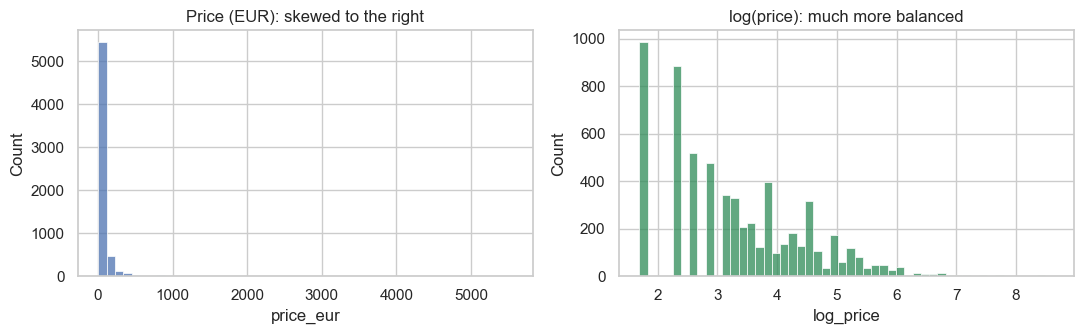

In [6]:
# Observation 1: prices are heavily skewed
mean_p, median_p = clean["price_eur"].mean(), clean["price_eur"].median()
skew = clean["price_eur"].skew()
print(f"Observation 1: mean price = EUR {mean_p:.2f} but median = EUR {median_p:.2f} (skewness {skew:.1f}).")
print("Most services are cheap and a few are very expensive, so we model log(price).")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(clean["price_eur"], bins=50, ax=ax[0]); ax[0].set_title("Price (EUR): skewed to the right")
sns.histplot(clean["log_price"], bins=50, ax=ax[1], color="seagreen"); ax[1].set_title("log(price): much more balanced")
plt.tight_layout(); plt.show()

In [7]:
# Observation 2: prices come in fixed steps, not a smooth range
n_unique = clean["price_eur"].nunique()
top5 = clean["price_eur"].value_counts(normalize=True).head(5)
print(f"Observation 2: only {n_unique} different prices exist in {len(clean)} rows.")
print("The 5 most common prices cover", f"{top5.sum():.0%}", "of all services:")
print(top5.round(3).to_string())
print("Sellers pick from set price tiers, so the model will predict an estimate, not an exact tier.")

Observation 2: only 142 different prices exist in 6182 rows.
The 5 most common prices cover 52% of all services:
price_eur
4.44     0.159
8.89     0.143
13.33    0.083
17.78    0.077
22.22    0.055
Sellers pick from set price tiers, so the model will predict an estimate, not an exact tier.


Observation 3: median price differs a lot between categories:
                       count  median    mean
Category                                    
Video & Animation       1248   35.55  100.50
Programming & Tech       807   31.11  115.26
Business                 720   26.66   62.66
Writing & Translation   1440   26.66   57.36
Digital Marketing        336   26.66   46.44
Music & Audio            768   22.22   41.43
Lifestyle                863    8.89   16.64


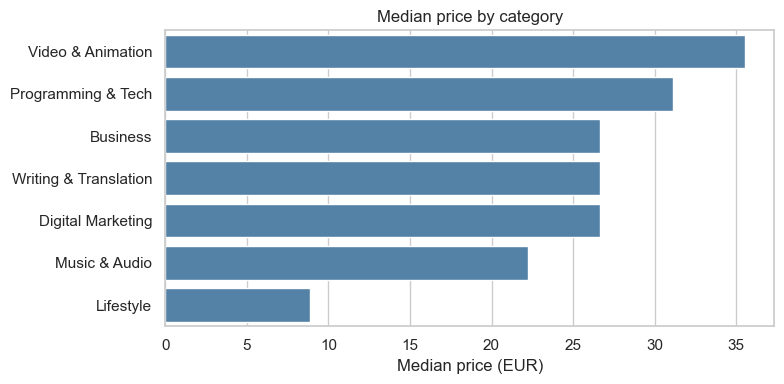

In [8]:
# Observation 3: some categories are clearly more expensive than others
cat_stats = clean.groupby("Category")["price_eur"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)
print("Observation 3: median price differs a lot between categories:")
print(cat_stats.round(2).to_string())

plt.figure(figsize=(8, 4))
sns.barplot(x=cat_stats["median"], y=cat_stats.index, color="steelblue")
plt.xlabel("Median price (EUR)"); plt.ylabel(""); plt.title("Median price by category")
plt.tight_layout(); plt.show()

Observation 4: 96% of rated services have a rating of 4.8 or more (median 5.0).
Because nearly everyone is rated highly, rating alone cannot tell a cheap service from an expensive one.


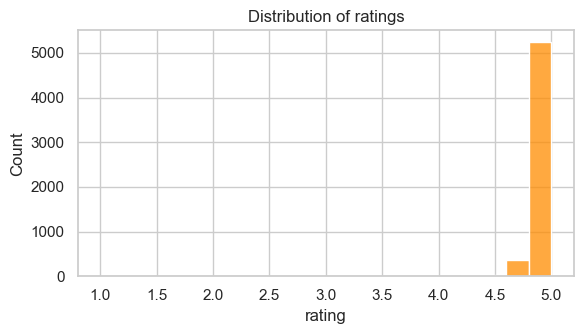

In [9]:
# Observation 4: ratings are almost all very high, so they say little about price
rated = clean["rating"].dropna()
share_high = (rated >= 4.8).mean()
print(f"Observation 4: {share_high:.0%} of rated services have a rating of 4.8 or more (median {rated.median():.1f}).")
print("Because nearly everyone is rated highly, rating alone cannot tell a cheap service from an expensive one.")

plt.figure(figsize=(6, 3.5))
sns.histplot(rated, bins=20, color="darkorange"); plt.title("Distribution of ratings")
plt.tight_layout(); plt.show()

In [10]:
# Observation 5: some services have no reviews yet, and review count (our stand-in for demand) has only a weak link to price
missing_share = (1 - clean.groupby("Category")["has_reviews"].mean()).sort_values(ascending=False)
print("Observation 5a: share of services with NO reviews yet, per category:")
print((missing_share * 100).round(1).astype(str).add("%").to_string())

corr = clean[["price_eur", "reviews", "rating"]].corr(method="spearman")
print("\nObservation 5b: Spearman correlation with price:")
print(corr["price_eur"].round(3).to_string())
print(f"Review count has only a weak link with price (correlation {corr.loc['price_eur', 'reviews']:.2f}); rating has almost none ({corr.loc['price_eur', 'rating']:.2f}).")
print("(Review count is our only stand-in for 'demand'. The dataset has no time, expertise or complexity columns.)")

Observation 5a: share of services with NO reviews yet, per category:
Category
Programming & Tech       10.4%
Digital Marketing         8.9%
Video & Animation         8.7%
Writing & Translation     8.5%
Lifestyle                 7.2%
Business                  6.8%
Music & Audio             4.9%

Observation 5b: Spearman correlation with price:
price_eur    1.000
reviews      0.108
rating      -0.005
Review count has only a weak link with price (correlation 0.11); rating has almost none (-0.01).
(Review count is our only stand-in for 'demand'. The dataset has no time, expertise or complexity columns.)


In [11]:
# Observation 6: the data is not balanced across categories
print("Observation 6: number of services per category")
print(clean["Category"].value_counts().to_string())
print("\nServices per sub-category: smallest =", clean["Subcat"].value_counts().min(),
      "| largest =", clean["Subcat"].value_counts().max())
print("Sub-categories are almost equal in size, but categories are not (e.g. Digital Marketing has far fewer services than Writing & Translation).")

Observation 6: number of services per category
Category
Writing & Translation    1440
Video & Animation        1248
Lifestyle                 863
Programming & Tech        807
Music & Audio             768
Business                  720
Digital Marketing         336

Services per sub-category: smallest = 39 | largest = 48
Sub-categories are almost equal in size, but categories are not (e.g. Digital Marketing has far fewer services than Writing & Translation).


**Summary of EDA findings**
1. Price is strongly right-skewed, so we predict `log(price)`.
2. Prices sit on a small set of fixed tiers.
3. Category matters for price (Lifestyle is much cheaper than the rest), so category and sub-category are useful features.
4. Ratings are nearly all high, so they will add little.
5. Some sellers have no reviews; we handle this with a "has reviews" flag. Review count has only a weak link with price.
6. Categories are unevenly represented, so we judge the model with cross-validation and not on one lucky split.

## 4. Modelling: Ridge Regression

**Why Ridge?** It is linear regression with a penalty (`alpha`) that stops the model from relying too heavily on any one feature. We have thousands of text and category columns but only about 6,000 rows, so without this penalty the model would memorise the training data (overfit). `alpha` controls how strong the penalty is: too small = overfitting, too large = underfitting.

**Features (what the model sees)**
| Feature | Meaning in our app |
|---|---|
| Category, Sub-category | what kind of service it is |
| Service title (as word scores, TF-IDF) | stand-in for expertise and complexity (e.g. "website", "legal") |
| Rating | quality |
| log(reviews), has-reviews flag | stand-in for demand and trust |

**Target:** `log(price)`

In [12]:
num_cols = ["rating", "log_reviews", "has_reviews"]
cat_cols = ["Category", "Subcat"]
text_col = "service"

X = clean[num_cols + cat_cols + [text_col]]
y = clean["log_price"]

# 80% to train, 20% kept aside as a final unseen test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

def make_preprocessor():
    # Turns our columns into numbers the model can use.
    # Everything (including the missing-rating fill) is learned from training data only.
    return ColumnTransformer([
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("txt", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=3000, stop_words="english"), text_col),
    ])

Training rows: 4945 | Test rows: 1237


In [13]:
# Helper to score a fitted model. Errors are shown in log space and converted back to euros.
def evaluate(model, X_data, y_log, label):
    pred_log = model.predict(X_data)
    return {
        "Model": label,
        "RMSE (log)": np.sqrt(mean_squared_error(y_log, pred_log)),
        "R2": r2_score(y_log, pred_log),
        "MAE (EUR)": mean_absolute_error(np.expm1(y_log), np.expm1(pred_log)),
        "Median error (EUR)": median_absolute_error(np.expm1(y_log), np.expm1(pred_log)),
    }

# A "model" that always predicts the average. Our real model must beat this.
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_scores = evaluate(baseline, X_test, y_test, "Baseline (always the average)")
baseline_scores

{'Model': 'Baseline (always the average)',
 'RMSE (log)': np.float64(1.1575634808720279),
 'R2': -0.0011933323939701257,
 'MAE (EUR)': 51.40082480540842,
 'Median error (EUR)': np.float64(16.818073686781226)}

In [14]:
# Ridge with 5-fold cross-validation to choose alpha.
# Cross-validation: the training data is split into 5 parts; the model trains on 4 and is checked on the 5th,
# rotating 5 times. This gives a more honest score than a single split.
ridge_pipe = Pipeline([("prep", make_preprocessor()), ("model", Ridge())])

param_grid = {"model__alpha": [0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(ridge_pipe, param_grid, cv=cv,
                    scoring="neg_root_mean_squared_error", return_train_score=True)
grid.fit(X_train, y_train)

best_alpha = grid.best_params_["model__alpha"]
best_idx = grid.best_index_
print("Best alpha:", best_alpha)
print(f"Cross-validated RMSE (log): {-grid.cv_results_['mean_test_score'][best_idx]:.3f} "
      f"(+/- {grid.cv_results_['std_test_score'][best_idx]:.3f} across the 5 folds)")

Best alpha: 5
Cross-validated RMSE (log): 0.961 (+/- 0.019 across the 5 folds)


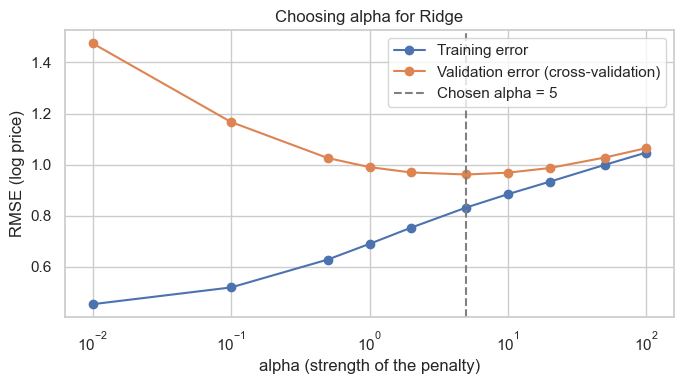

In [15]:
# Regularisation check: training error vs validation error for each alpha
res = pd.DataFrame(grid.cv_results_)
alphas = res["param_model__alpha"].astype(float)

plt.figure(figsize=(7, 4))
plt.plot(alphas, -res["mean_train_score"], marker="o", label="Training error")
plt.plot(alphas, -res["mean_test_score"], marker="o", label="Validation error (cross-validation)")
plt.axvline(best_alpha, color="grey", linestyle="--", label=f"Chosen alpha = {best_alpha}")
plt.xscale("log"); plt.xlabel("alpha (strength of the penalty)"); plt.ylabel("RMSE (log price)")
plt.title("Choosing alpha for Ridge"); plt.legend(); plt.tight_layout(); plt.show()

**How to read this graph:** with a tiny alpha the training error is very low but the validation error is higher. The model has memorised the training data and does worse on new data (overfitting). As alpha grows, the gap closes. We pick the alpha where validation error is lowest.

In [16]:
# Final check on the 20% test data the model has never seen
ridge_best = grid.best_estimator_
results = pd.DataFrame([baseline_scores, evaluate(ridge_best, X_test, y_test, f"Ridge (alpha={best_alpha})")])
results.round(3)

,Model,RMSE (log),R2,MAE (EUR),Median error (EUR)
0,Baseline (always the average),1.158,-0.001,51.401,16.818
1,Ridge (alpha=5),0.941,0.339,44.302,13.408


**What the results mean (in simple words)**
- The log-price error (RMSE) drops from about 1.16 (always guessing the average) to about 0.94 with Ridge, and R2 is about 0.34. So Ridge explains roughly a third of the differences in price. It is clearly better than guessing, but it is not very precise.
- The error in euros looks large because a few very expensive services dominate the average error (mean price is about EUR 66, median about EUR 22). The **median error** is a fairer measure of a typical mistake.
- Why the ceiling is low: sellers on Fiverr set their own price, and two services in the same sub-category often have very different prices. Our data only has the title, category, rating and review count, so much of the price variation cannot be explained.
- For the app, this means the estimate is best used as a **rough guide** for comparing two services (which is worth more, and roughly by how much), not as an exact price.

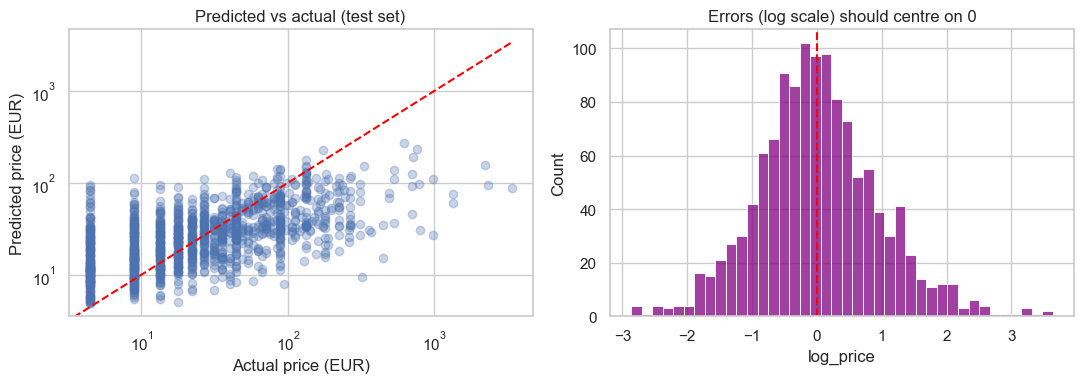

In [17]:
# Predicted vs actual price, and the errors (residuals)
pred_eur = np.expm1(ridge_best.predict(X_test))
actual_eur = np.expm1(y_test)
resid = np.log1p(actual_eur) - np.log1p(pred_eur)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(actual_eur, pred_eur, alpha=0.3)
lim = max(actual_eur.max(), pred_eur.max())
ax[0].plot([0, lim], [0, lim], color="red", linestyle="--")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Actual price (EUR)"); ax[0].set_ylabel("Predicted price (EUR)"); ax[0].set_title("Predicted vs actual (test set)")
sns.histplot(resid, bins=40, ax=ax[1], color="purple")
ax[1].axvline(0, color="red", linestyle="--"); ax[1].set_title("Errors (log scale) should centre on 0")
plt.tight_layout(); plt.show()

In [18]:
# Which features push the predicted price up or down the most?
names = ridge_best.named_steps["prep"].get_feature_names_out()
coefs = ridge_best.named_steps["model"].coef_
coef_df = pd.Series(coefs, index=names).sort_values()
print("Features that LOWER the predicted price most:")
print(coef_df.head(8).round(3).to_string())
print("\nFeatures that RAISE the predicted price most:")
print(coef_df.tail(8).round(3).to_string())

Features that LOWER the predicted price most:
cat__Subcat_Article to Video       -0.997
cat__Subcat_User Testing           -0.976
cat__Subcat_Subtitles & Captions   -0.934
cat__Subcat_Flyer Distribution     -0.876
txt__nature                        -0.817
txt__java                          -0.788
cat__Subcat_Transcripts            -0.786
cat__Subcat_Screencasting Videos   -0.760

Features that RAISE the predicted price most:
cat__Subcat_Whiteboard & Animated Explainers    0.819
cat__Subcat_Resume Writing                      0.845
txt__produce                                    0.903
cat__Subcat_Local Photography                   0.984
cat__Subcat_E-Commerce Development              1.008
txt__video course                               1.026
cat__Subcat_Cybersecurity & Data Protection     1.427
txt__studio                                     1.434


## 5. Using the model in the app: fair-exchange check
This is the app workflow from our slides, working on top of the trained model:
1. Estimate the value of each service in the swap.
2. If the values are close (within a tolerance), the swap is **fair**.
3. If not, suggest a **cash top-up** (the gap) or an **extra service** of roughly the gap's value.

**Important:** the dataset price is the *starting price* of a Fiverr listing in euros, so these are estimates for comparing services against each other, not exact local prices. Before launch, they should be calibrated with real Kenyan service prices.

In [19]:
def estimate_value(service, category, subcat, rating=np.nan, reviews=0):
    # Predict the price (EUR) of one service
    row = pd.DataFrame([{
        "rating": rating,
        "log_reviews": np.log1p(reviews),
        "has_reviews": int(reviews > 0),
        "Category": category,
        "Subcat": subcat,
        "service": service.lower(),
    }])
    return float(np.expm1(ridge_best.predict(row[X.columns]))[0])


def check_exchange(service_a, service_b, tolerance=0.15):
    # Compare two services. tolerance=0.15 means a gap of up to 15% of the bigger value counts as fair.
    value_a = estimate_value(**service_a)
    value_b = estimate_value(**service_b)
    gap = abs(value_a - value_b)
    gap_share = gap / max(value_a, value_b)

    print(f"Service A: {service_a['service']}  ->  EUR {value_a:.2f}")
    print(f"Service B: {service_b['service']}  ->  EUR {value_b:.2f}")

    if gap_share <= tolerance:
        print(f"\nFAIR EXCHANGE (gap is only {gap_share:.0%}).")
        return

    lower = "A" if value_a < value_b else "B"
    print(f"\nNOT EQUAL: gap of EUR {gap:.2f} ({gap_share:.0%}). Person {lower} is offering less.")
    print(f"Option 1: Person {lower} adds a cash top-up of about EUR {gap:.2f}.")

    # Option 2: real listings from the data whose price is closest to the gap
    closest = clean.iloc[(clean["price_eur"] - gap).abs().argsort()[:3]]
    print(f"Option 2: Person {lower} adds a small extra service of similar value, for example:")
    for _, r in closest.iterrows():
        print(f"   - {r['service']} ({r['Subcat']}), about EUR {r['price_eur']:.2f}")


# Demo 1: compare a legal-writing service with a website-design service
check_exchange(
    {"service": "write a gdpr privacy policy and terms", "category": "Writing & Translation", "subcat": "Legal Writing"},
    {"service": "design and redesign a wix website", "category": "Programming & Tech", "subcat": "Website Builders & CMS"},
)

Service A: write a gdpr privacy policy and terms  ->  EUR 26.94
Service B: design and redesign a wix website  ->  EUR 102.79

NOT EQUAL: gap of EUR 75.85 (74%). Person A is offering less.
Option 1: Person A adds a cash top-up of about EUR 75.85.
Option 2: Person A adds a small extra service of similar value, for example:
   - assist with your fca authorisation application and regulation (Business Plans), about EUR 75.55
   - write and record the best nursery rhymes for kids (Songwriters), about EUR 75.55
   - write and design your pdf book (Book & eBook Writing), about EUR 75.55


In [20]:
# Demo 2: compare a transcription service with a podcast-editing service
check_exchange(
    {"service": "transcribe english audio files", "category": "Writing & Translation", "subcat": "Transcripts"},
    {"service": "edit and master your podcast", "category": "Music & Audio", "subcat": "Podcast Editing"},
)

Service A: transcribe english audio files  ->  EUR 9.25
Service B: edit and master your podcast  ->  EUR 18.87

NOT EQUAL: gap of EUR 9.62 (51%). Person A is offering less.
Option 1: Person A adds a cash top-up of about EUR 9.62.
Option 2: Person A adds a small extra service of similar value, for example:
   - record my impersonation of donald trump (Celebrity Impersonators), about EUR 8.89
   - do classified ad posting on top usa, uk, canada ad sites (Flyer Distribution), about EUR 8.89
   - provide music law and entertainment law, contracts and services (Legal Consulting), about EUR 8.89


## 6. Validation plan: other models to compare against (Question 4)
One model's score on its own does not prove much. To check that Ridge is a sound choice, we train other models using **exactly the same process** (same cleaning, same features, same 5-fold cross-validation, same test set) and compare the results.

| Model | Why we are trying it |
|---|---|
| Baseline (average) | the minimum bar any model must beat |
| **Ridge** (base model) | keeps all features, shrinks their weights |
| Lasso | also regularises, but sets unhelpful features to zero, so it shows which features really matter |
| Random Forest | handles non-linear patterns (e.g. a word only matters inside one category) that a linear model misses |

We also check the Ridge residuals (errors) for patterns, and compare errors per category to see where the model is weak.
The comparison below is a first version; the final version will be completed for the end of the project.

In [21]:
models = {
    "Ridge (base)": (Ridge(), {"model__alpha": [0.1, 1, 5, 10, 20]}),
    "Lasso": (Lasso(max_iter=10000), {"model__alpha": [0.0005, 0.001, 0.005, 0.01, 0.05]}),
    "Random Forest": (RandomForestRegressor(n_estimators=100, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1), None),
}

rows = [baseline_scores]
for name, (estimator, grid_params) in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", estimator)])
    if grid_params:
        search = GridSearchCV(pipe, grid_params, cv=cv, scoring="neg_root_mean_squared_error")
        search.fit(X_train, y_train)
        fitted = search.best_estimator_
        label = f"{name} {search.best_params_}"
        cv_rmse = -search.best_score_
    else:
        fitted = pipe.fit(X_train, y_train)
        label = name
        cv_scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
        cv_rmse = -cv_scores["test_score"].mean()
    scores = evaluate(fitted, X_test, y_test, label)
    scores["CV RMSE (log)"] = cv_rmse
    rows.append(scores)

comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(3)

,RMSE (log),R2,MAE (EUR),Median error (EUR),CV RMSE (log)
Model,,,,,
Baseline (always the average),1.158,-0.001,51.401,16.818,NaN
Ridge (base) {'model__alpha': 5},0.941,0.339,44.302,13.408,0.961
Lasso {'model__alpha': 0.0005},0.946,0.331,44.632,13.765,0.971
Random Forest,0.944,0.333,44.531,13.397,0.970


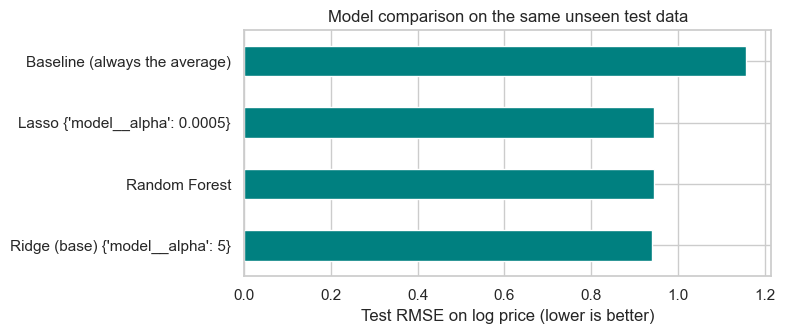

In [22]:
plt.figure(figsize=(8, 3.5))
comparison["RMSE (log)"].sort_values().plot(kind="barh", color="teal")
plt.xlabel("Test RMSE on log price (lower is better)"); plt.ylabel("")
plt.title("Model comparison on the same unseen test data")
plt.tight_layout(); plt.show()

**What the comparison shows:** Ridge, Lasso and Random Forest score almost the same (test RMSE about 0.94 to 0.95; R2 about 0.33 to 0.34). The gaps between them are smaller than the fold-to-fold variation in cross-validation (about 0.02), so we cannot say any model is truly better. This is a useful result: it suggests the limit comes from the **data** (what the listings tell us), not from the choice of algorithm. We keep Ridge as the base model because it is the simplest and easiest to explain. For the final project, we can try adding more informative features (for example, extra text features from the title) and see whether all models improve together.

## Limitations and next steps
- **Starting price, not average price.** Each row is the cheapest package of a listing, so estimates are a lower-bound style value.
- **Modest accuracy.** Ridge explains about a third of the variation in price (R2 about 0.34). Use the estimates as a rough guide, not an exact price.
- **Missing value factors.** Time, expertise, complexity and demand from our slides are not columns in this dataset. We use the service title and review count as proxies.
- **Euro prices from a global platform.** Estimates should be calibrated with Kenyan service prices (for example, data collected from our own app users).
- **Next:** complete the model comparison and error analysis for the final project, and build the second AI feature (the recommender: suggest providers and swap partners using skills, location and ratings).